# Change Analysis

> Are we seeing any lead quality trends over time (improving declining)? Are they statistically significant?

In [2]:
import numpy as np
import pandas as pd

data = pd.read_parquet('processed/df1_preproc.parquet')

Denote $Y_t \in \{0,1,2,\dots,7\}$ as the $t^\text{th}$ observation (where $t = (\text{time}, \text{agent})$, since multiple observations occur on the same indistinguishable date).

To investigate whether lead quality changes over time, we first aggregate the observations into weekly and monthly periods. The dataset covers approximately 181 days, from 2 April 2009 to 30 September 2009. This gives us 27 weekly and 6 monthly observations, the former amongst which is sufficient for a cautious offline changepoint analysis, but is still a relatively short time series for detecting complex temporal structure.

In [3]:
import matplotlib.pyplot as plt

callstatus = data[['CallStatusNo', 'Date']].dropna()

callstatus_daily = (
    callstatus.groupby([pd.Grouper(key='Date', freq='D'), 'CallStatusNo'])
    .size()
    .unstack(fill_value=0)
)

callstatus_weekly = (
    callstatus.groupby([pd.Grouper(key='Date', freq='W-MON'), 'CallStatusNo'])
    .size()
    .unstack(fill_value=0)
)

callstatus_weekly_norm = callstatus_weekly.div(callstatus_weekly.sum(axis=1), axis=0)

callstatus_monthly = (
    callstatus.groupby([pd.Grouper(key='Date', freq='ME'), 'CallStatusNo'])
    .size()
    .unstack(fill_value=0)
)

callstatus_monthly_norm = callstatus_monthly.div(callstatus_monthly.sum(axis=1), axis=0)

We consider two notions of lead quality throughout this analysis. A *qualified lead* is defined as a lead for which
$$ Y_t \in\{4,5,6,7\} $$
while a *closed lead* is one for which
\[Y_t = 7\]

The latter is the more commercially relevant measure of lead quality, since it corresponds to the final closed outcome.

## Plots

To answer the question, let us first aggregate the data into weekly sums and examine how the different outcomes change through time:

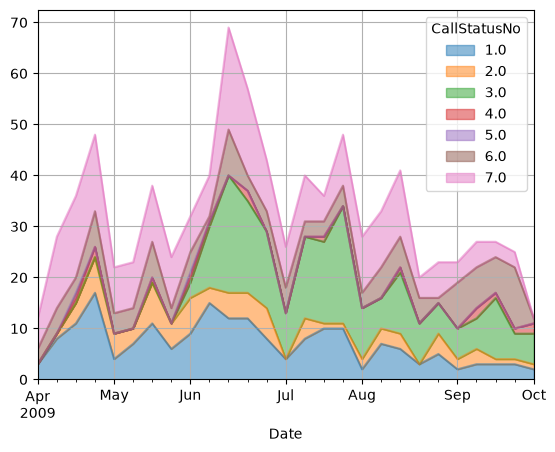

In [4]:
callstatus_weekly.plot(kind='area', stacked=True, alpha=0.5)
plt.grid(True)

The corresponding weekly proportions are shown below. Here, each outcome count is divided by the total number of leads received during that week, so that changes in lead volume are separated from changes in the composition of outcomes.

<Axes: xlabel='Date'>

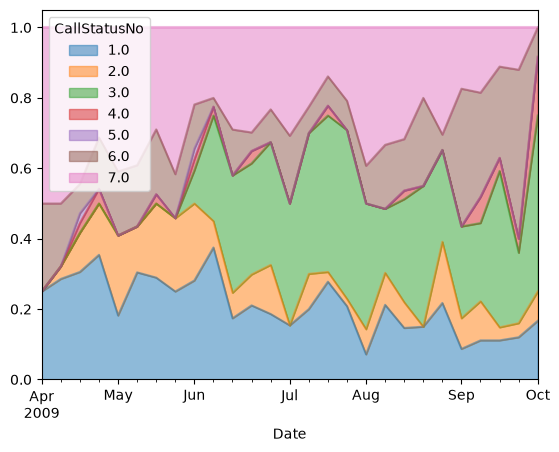

In [5]:
callstatus_weekly_norm.plot(kind='area', stacked=True, alpha=0.5)

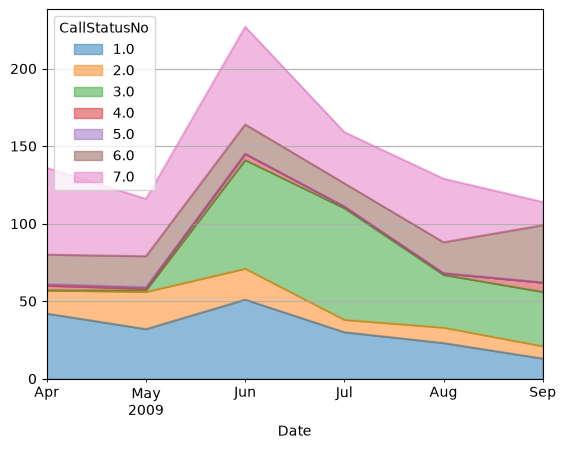

In [6]:
callstatus_monthly.plot(kind='area', stacked=True, alpha=0.5)
plt.grid(True)

<Axes: xlabel='Date'>

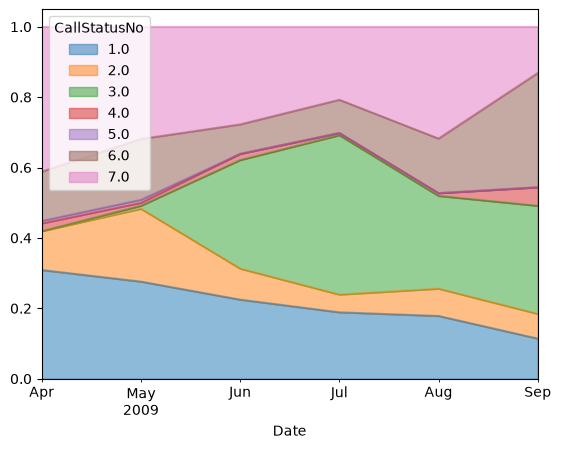

In [7]:
callstatus_monthly_norm.plot(kind='area', stacked=True, alpha=0.5)

The figures suggest that the time series is not adequately described by a simple linear trend. In particular, the proportion of leads that eventually become closed appears to fall substantially during the latter part of the observation period. The qualified-lead proportion is considerably more stable, although it also exhibits substantial week-to-week variation.

## Changepoint Analysis

Because the observation period is short, we restrict the formal changepoint analysis to weekly observations. Monthly aggregation would leave only approximately six observations, which is insufficient for reliable offline changepoint detection.

The objective of changepoint analysis is to determine whether the underlying rate of an outcome appears to change abruptly at some point in time.

For a sequence of observations $Y_1,\ldots,Y_N$, a changepoint at $\tau$ separates the observations into two regimes:

$$
Y_1,\ldots,Y_{\tau}
\qquad\text{and}\qquad
Y_{\tau+1},\ldots,Y_N.
$$

We use the PELT (Pruned Exact Linear Time) algorithm to identify candidate changepoints. PELT minimizes a penalized segmentation criterion and, under suitable regularity conditions, obtains the exact optimum efficiently through pruning. Strictly speaking, its worst-case computational complexity need not be linear; the linear-time characterization refers to the expected behaviour under conditions where the pruning is effective.

CallStatusNo 1.0 Changepoints: ['2009-08-17']
CallStatusNo 2.0 Changepoints: ['2009-07-13']
CallStatusNo 3.0 Changepoints: ['2009-05-04', '2009-06-08', '2009-08-17']
CallStatusNo 4.0 Changepoints: []
CallStatusNo 5.0 Changepoints: []
CallStatusNo 6.0 Changepoints: []
CallStatusNo 7.0 Changepoints: ['2009-08-17']


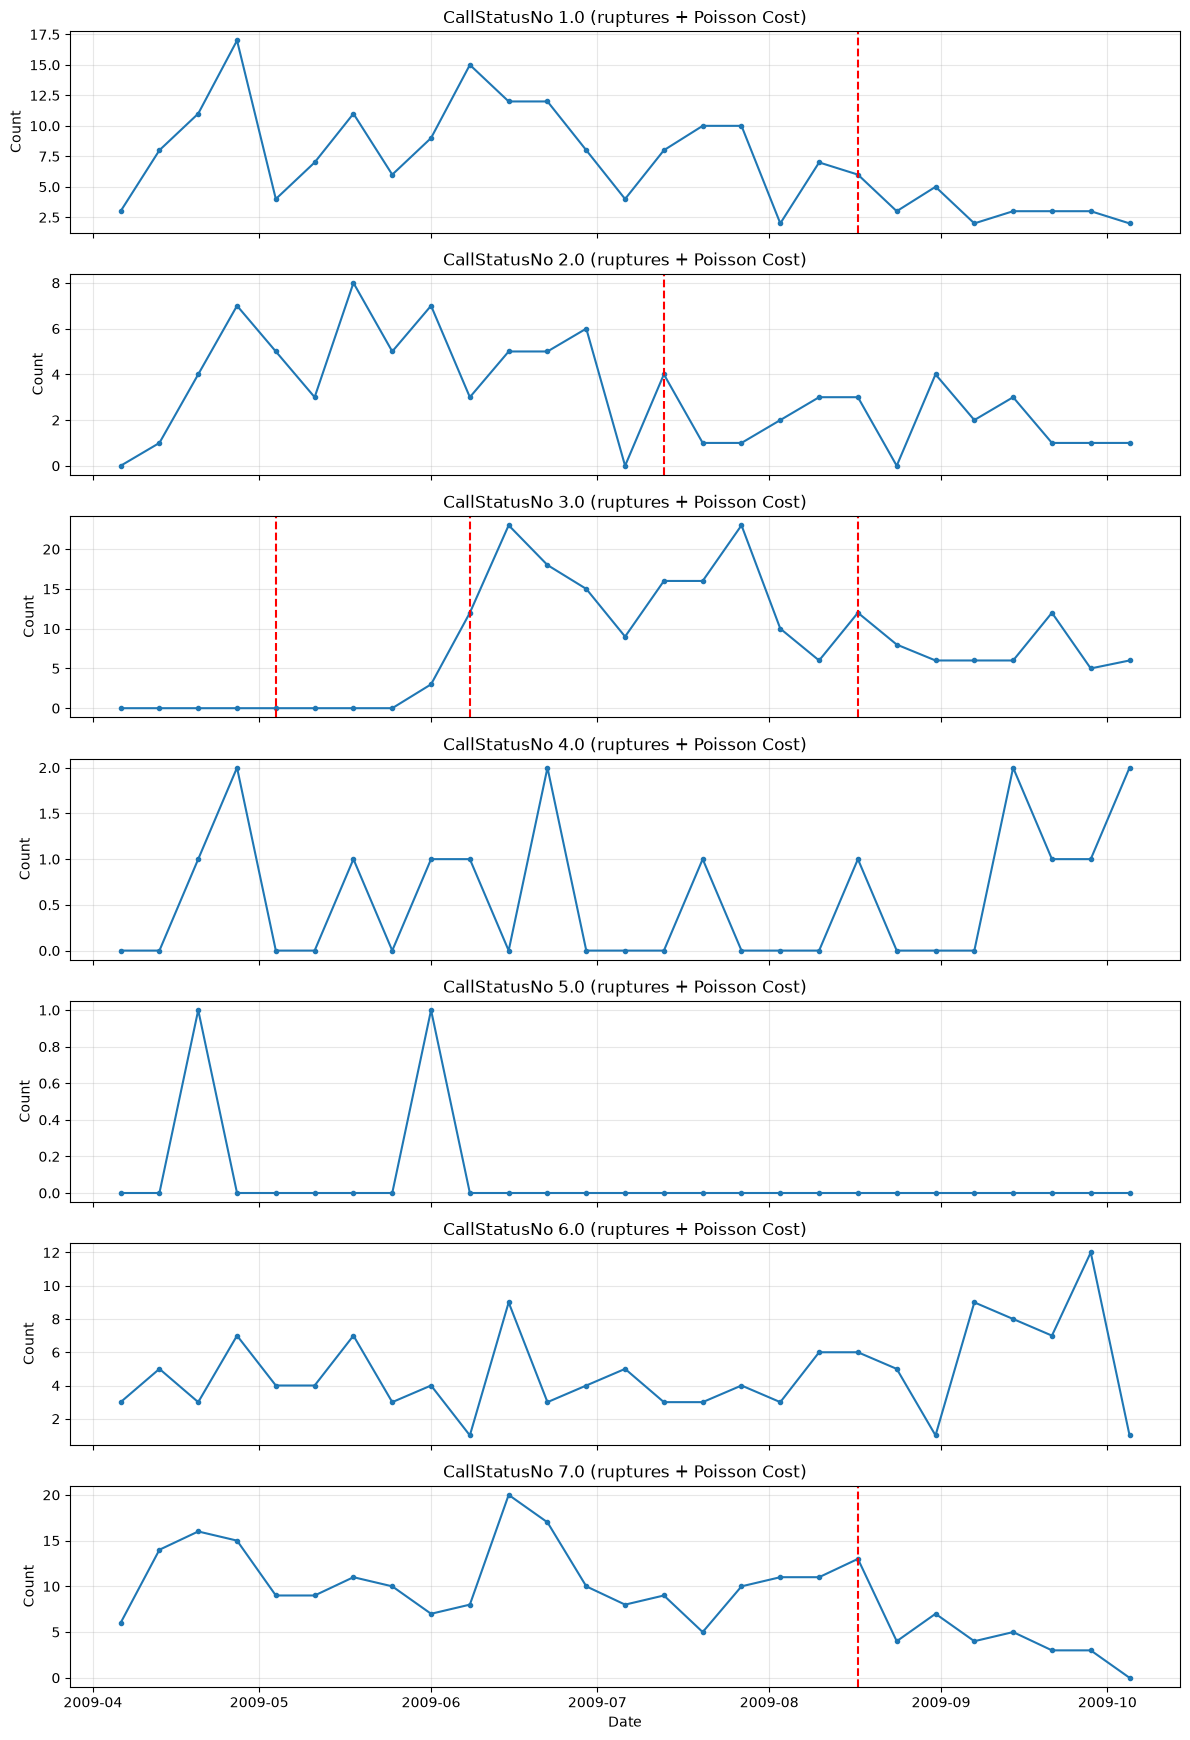

In [8]:
import matplotlib.pyplot as plt
import ruptures as rpt


# 1. Inherit from rpt.base.BaseCost
class CostPoisson(rpt.base.BaseCost):
    """Custom Poisson deviance cost for event count data."""
    model = "poisson"
    min_size = 1

    def fit(self, signal):
        self.signal = np.asarray(signal, dtype=float).flatten()
        self.sum_signal = np.zeros(len(self.signal) + 1)
        self.sum_signal[1:] = np.cumsum(self.signal)
        return self

    def error(self, start, end):
        sub_sum = self.sum_signal[end] - self.sum_signal[start]
        n_obs = end - start
        
        if sub_sum <= 0:
            return 0.0
            
        lam = sub_sum / n_obs
        return 2.0 * (n_obs * lam - sub_sum * np.log(lam))

# 2. Prepare dataset
df_weekly = callstatus_weekly.copy()
df_weekly.index = pd.to_datetime(df_weekly.index)

### On Counts

In [ ]:

results = {}
penalty_val = 10.0  # Adjust as needed

# 3. Fit PELT using ruptures with CostPoisson
for col in df_weekly.columns:
    signal = df_weekly[col].values
    
    cost_obj = CostPoisson().fit(signal)
    algo = rpt.Pelt(custom_cost=cost_obj, min_size=2).fit(signal)
    
    bkps = algo.predict(pen=penalty_val)
    
    cp_dates = [df_weekly.index[i - 1].strftime('%Y-%m-%d') for i in bkps if i < len(df_weekly)]
    results[col] = cp_dates
    print(f"CallStatusNo {col} Changepoints:", cp_dates)

# 4. Plot results
fig, axes = plt.subplots(len(df_weekly.columns), 1, figsize=(12, 2.5 * len(df_weekly.columns)), sharex=True)

if len(df_weekly.columns) == 1:
    axes = [axes]

for ax, col in zip(axes, df_weekly.columns):
    ax.plot(df_weekly.index, df_weekly[col], label=f'Status {col}', color='tab:blue', marker='o', markersize=3)
    
    for cp_date in results[col]:
        ax.axvline(x=pd.to_datetime(cp_date), color='red', linestyle='--', linewidth=1.5)
        
    ax.set_title(f"CallStatusNo {col} (ruptures + Poisson Cost)")
    ax.set_ylabel("Count")
    ax.grid(True, alpha=0.3)

plt.xlabel("Date")
plt.tight_layout()
plt.show()


Weekly outcome counts are naturally treated as discrete non-negative event counts, for which a Poisson model is a natural first approximation. For a segment \(S\), we therefore use the Poisson negative log-likelihood as the segment cost.

If
$$
Y_t\sim\operatorname{Poisson}(\lambda)
$$
within a segment, the maximum-likelihood estimate of the segment rate is
$$
\widehat{\lambda} = \frac{1}{|S|} \sum_{t\in S}Y_t
$$

Ignoring constants which do not depend on the segmentation, the corresponding Poisson deviance cost is
$$
D(S)
=
2\sum_{t\in S}
\left[
Y_t\log\left(\frac{Y_t}{\widehat{\lambda}}\right)
-
(Y_t-\widehat{\lambda})
\right]
$$

We apply PELT to the weekly counts of qualified and closed leads. Using a conservative penalty of \(2\log N\), the closed-lead count series produces a prominent changepoint at the week beginning

$$
\boxed{\text{17 August 2009}}.
$$

The qualified-lead counts show weaker evidence of temporal segmentation, with candidate changes occurring around June and August. However, these changes must be interpreted cautiously because the total number of leads received per week also changes considerably.

This distinction is important. A reduction in the number of closed leads does not necessarily imply a deterioration in lead quality if the number of leads entering the system has simultaneously fallen. Consequently, the count analysis is primarily useful for identifying candidate periods of structural change rather than for making the final statement about lead quality.


### On Proportions

For lead quality, proportions are more appropriate than raw counts. Let \(n_t\) denote the number of leads received in week \(t\), and let \(Y_t\) denote the number of closed leads. We model

\[
Y_t\sim\operatorname{Binomial}(n_t,p_t),
\]

where \(p_t\) is the probability that a lead received during week \(t\) becomes closed.

This formulation explicitly accounts for the changing number of leads in each week.

Applying a penalized changepoint analysis to the weekly proportions again identifies the week beginning 17 August 2009 as the strongest candidate changepoint for closed-lead quality. In contrast, no comparably strong changepoint is found for the qualified-lead rate under the same conservative penalty.

The magnitude of the change is substantial. Before 17 August, the data contain 2,471 leads, of which 218 become closed, giving a closed rate of

\[
\frac{218}{2471}=8.82\%.
\]

From 17 August onward, there are 550 leads, of which only 27 become closed:

\[
\frac{27}{550}=4.91\%.
\]

Thus, the estimated closed-lead rate falls by approximately

\[
8.82\%-4.91\%=3.91
\]

percentage points, corresponding to a relative decline of approximately

\[
\frac{4.91-8.82}{8.82}\times100
\approx -44.3\%.
\]

The qualified-lead rate, on the other hand, changes from

\[
12.79\%
\]

before the candidate changepoint to

\[
14.00\%
\]

afterwards. This difference is not statistically significant.

To account for the fact that the changepoint was selected by searching over many possible weeks, we assess the strongest candidate changepoint using a parametric bootstrap under the null hypothesis of a constant underlying rate. For the closed-lead series, the maximum likelihood-ratio statistic is approximately

\[
10.35,
\]

with a bootstrap-adjusted \(p\)-value of approximately

\[
p=0.012.
\]

Hence, there is statistically significant evidence of a structural change in the closed-lead rate around 17 August 2009.

For the qualified-lead rate, the strongest candidate split occurs around 3 August 2009, but its likelihood-ratio statistic is only approximately \(4.36\), with a bootstrap-adjusted \(p\)-value of approximately

\[
p=0.23.
\]

Thus, we do not have sufficient evidence to conclude that the qualified-lead rate experienced a genuine changepoint.

It is also useful to fit a simple Poisson regression with the logarithm of weekly lead volume as an offset. This tests for a smooth temporal trend in the outcome rate rather than an abrupt changepoint. For qualified leads, the estimated weekly rate ratio is approximately \(1.003\) with \(p=0.68\), providing essentially no evidence of a monotone temporal trend. For closed leads, the estimated weekly rate ratio is approximately \(0.978\), corresponding to an estimated decline of about \(2.2\%\) per week, with

\[
p=0.015.
\]

The two analyses therefore tell a consistent story: there is evidence that closed-lead quality deteriorates over the observation period, and the deterioration becomes particularly pronounced around August.

=== Detected Changepoints per Call Status ===
CallStatusNo 1.0: ['2009-07-13', '2009-08-17']
CallStatusNo 2.0: ['2009-07-13']
CallStatusNo 3.0: ['2009-05-04', '2009-06-08', '2009-07-13', '2009-08-17']
CallStatusNo 4.0: []
CallStatusNo 5.0: []
CallStatusNo 6.0: ['2009-08-17']
CallStatusNo 7.0: ['2009-05-04', '2009-06-08', '2009-07-13', '2009-08-17', '2009-09-21']


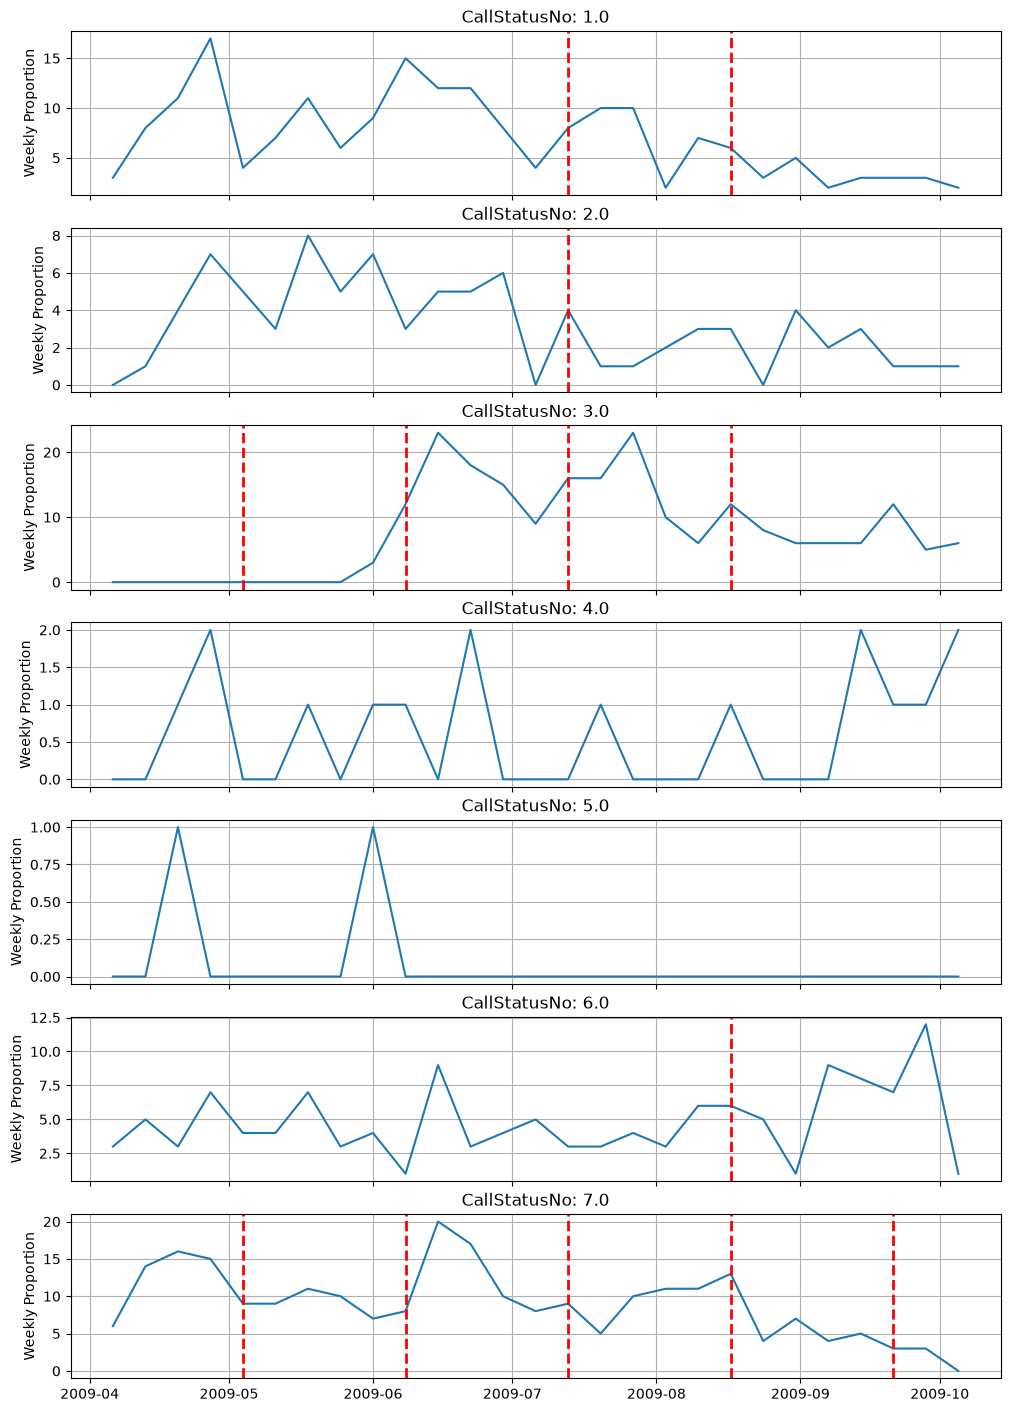

In [9]:
# 1. Ensure index is Datetime for proper plotting
df_weekly = callstatus_weekly.copy()
df_weekly.index = pd.to_datetime(df_weekly.index)

# Dictionary to store results for each status
results = {}

# 2. Perform Changepoint Analysis for each CallStatusNo column
for col in df_weekly.columns:
    series = df_weekly[col]
    signal = series.values
    
    # Run PELT algorithm
    algo = rpt.Pelt(model="l2", min_size=2).fit(signal)
    # Adjust penalty 'pen' if you want fewer (higher pen) or more (lower pen) points
    bkps = algo.predict(pen=10) 
    
    # Map index positions to actual string dates
    cp_dates = [df_weekly.index[i - 1].strftime('%Y-%m-%d') for i in bkps if i < len(df_weekly)]
    results[col] = cp_dates

# Print detected changepoints per call status category
print("=== Detected Changepoints per Call Status ===")
for status, dates in results.items():
    print(f"CallStatusNo {status}: {dates}")

# 3. Plot each CallStatusNo with its detected changepoints
fig, axes = plt.subplots(len(df_weekly.columns), 1, figsize=(12, 2.5 * len(df_weekly.columns)), sharex=True)

for ax, col in zip(axes, df_weekly.columns):
    ax.plot(df_weekly.index, df_weekly[col], label=f'Status {col}', color='tab:blue')
    
    # Draw vertical red lines at changepoints
    for cp_str in results[col]:
        cp_dt = pd.to_datetime(cp_str)
        ax.axvline(x=cp_dt, color='red', linestyle='--', linewidth=2)
        
    ax.set_title(f"CallStatusNo: {col}")
    ax.set_ylabel("Weekly Proportion")
    ax.grid(True)


=== Detected Changepoints per Call Status ===
CallStatusNo 1.0: []
CallStatusNo 2.0: []
CallStatusNo 3.0: []
CallStatusNo 4.0: []
CallStatusNo 5.0: []
CallStatusNo 6.0: []
CallStatusNo 7.0: []


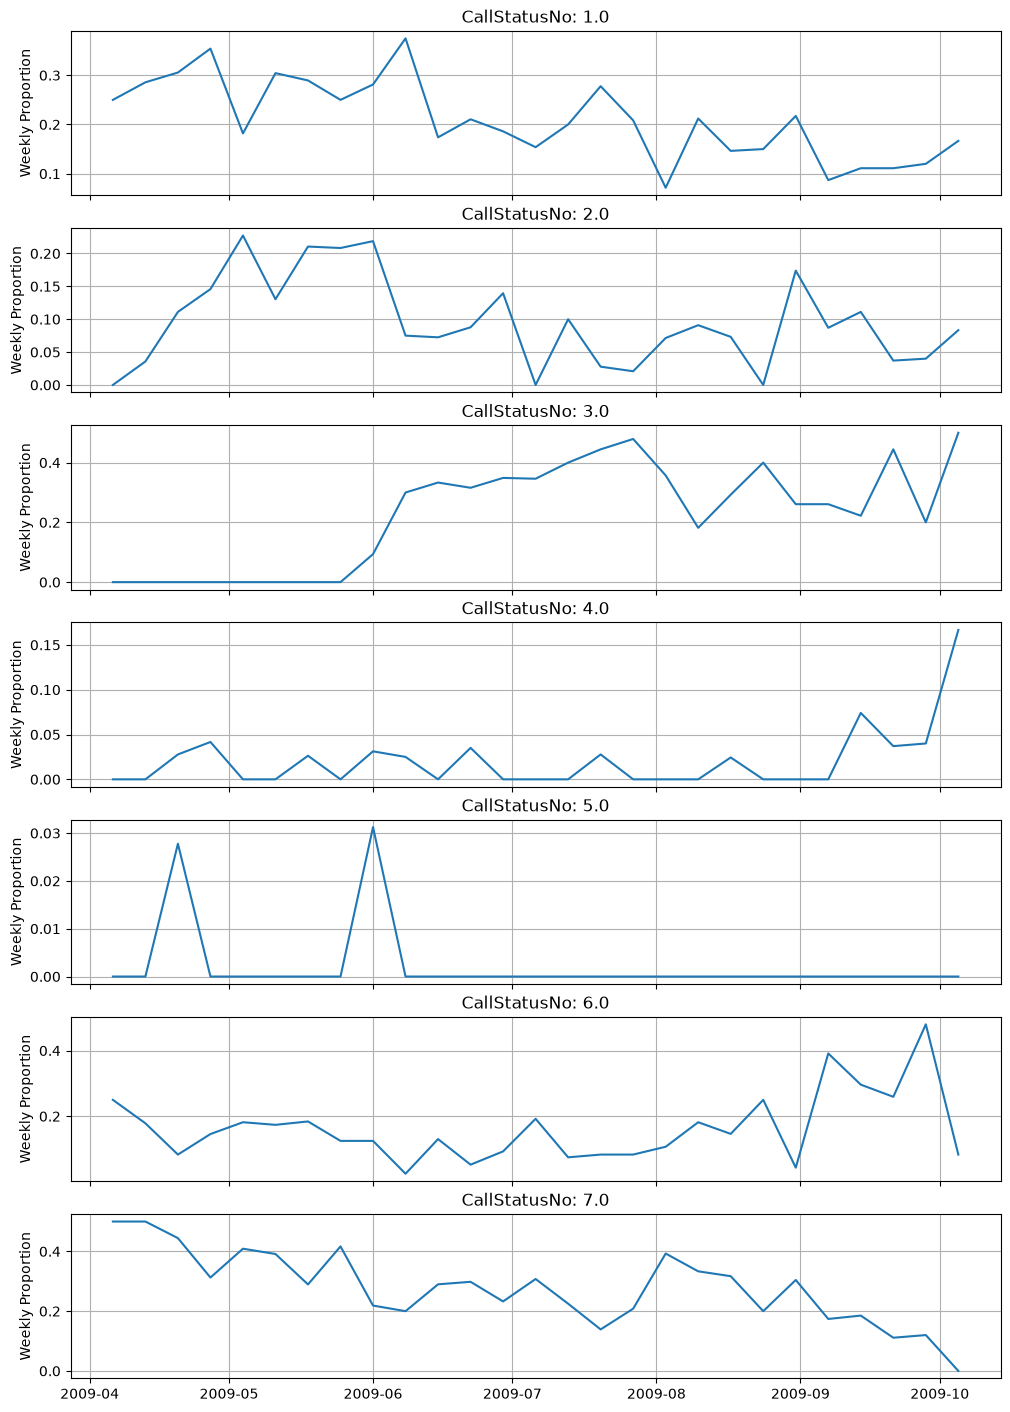

In [10]:
# 1. Ensure index is Datetime for proper plotting
df_weekly = callstatus_weekly_norm.copy()
df_weekly.index = pd.to_datetime(df_weekly.index)

# Dictionary to store results for each status
results = {}

# 2. Perform Changepoint Analysis for each CallStatusNo column
for col in df_weekly.columns:
    series = df_weekly[col]
    signal = series.values
    
    # Run PELT algorithm
    algo = rpt.Pelt(model="l2", min_size=2).fit(signal)
    # Adjust penalty 'pen' if you want fewer (higher pen) or more (lower pen) points
    bkps = algo.predict(pen=10) 
    
    # Map index positions to actual string dates
    cp_dates = [df_weekly.index[i - 1].strftime('%Y-%m-%d') for i in bkps if i < len(df_weekly)]
    results[col] = cp_dates

# Print detected changepoints per call status category
print("=== Detected Changepoints per Call Status ===")
for status, dates in results.items():
    print(f"CallStatusNo {status}: {dates}")

# 3. Plot each CallStatusNo with its detected changepoints
fig, axes = plt.subplots(len(df_weekly.columns), 1, figsize=(12, 2.5 * len(df_weekly.columns)), sharex=True)

for ax, col in zip(axes, df_weekly.columns):
    ax.plot(df_weekly.index, df_weekly[col], label=f'Status {col}', color='tab:blue')
    
    # Draw vertical red lines at changepoints
    for cp_str in results[col]:
        cp_dt = pd.to_datetime(cp_str)
        ax.axvline(x=cp_dt, color='red', linestyle='--', linewidth=2)
        
    ax.set_title(f"CallStatusNo: {col}")
    ax.set_ylabel("Weekly Proportion")
    ax.grid(True)


### Interpretation

# Bayesian Changepoint Analysis

As a complementary analysis, we perform a Bayesian single-changepoint analysis. For each possible changepoint \(\tau\), the weeks before and after \(\tau\) are assumed to have different underlying lead-quality probabilities:

\[
p_t =
\begin{cases}
	p_1, & t\leq\tau,\\
	p_2, & t>\tau.
\end{cases}
\]

For the closed-lead outcome we use

\[
Y_t\mid p_t\sim\operatorname{Binomial}(n_t,p_t)
\]

and assign independent uniform Beta priors,

\[
p_1,p_2\sim\operatorname{Beta}(1,1).
\]

The resulting posterior distribution over the possible changepoint locations places its highest posterior mass at the week beginning 17 August 2009. Approximately \(33\%\) of the posterior probability is assigned to this particular changepoint, with additional posterior mass assigned to neighbouring weeks in late August and September.

This posterior distribution is considerably more diffuse than would be desirable with a longer time series. This is expected given that only 27 weekly observations are available.

For comparison, the Bayesian analysis of the qualified-lead rate does not produce a similarly concentrated posterior. Its posterior mode occurs later in the observation period and the posterior mass is spread over several candidate dates.

The Bayesian analysis therefore supports the interpretation obtained from the frequentist analysis: the evidence for a change in \emph{closed-lead quality} is substantially stronger than the evidence for a change in qualified-lead quality.

However, the Bayesian evidence should not be overstated. With a uniform prior over possible changepoints, the Bayes factor comparing a single-changepoint model with a no-changepoint model is approximately \(0.59\) for closed leads and \(0.13\) for qualified leads. Thus, after averaging over all possible changepoint locations and applying the corresponding Occam penalty, the evidence is not overwhelming.

This is not contradictory to the frequentist result. The frequentist analysis asks whether the \emph{best-fitting} changepoint produces an unusually large improvement in fit, whereas the Bayesian model averages over all possible changepoint locations. With only 27 observations, this averaging imposes a substantial penalty on the more flexible changepoint model.


Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [tau]
>NUTS: [lambda_1, lambda_2]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Status 1.0 MAP Changepoint Date: 2009-08-03
  Pre-shift Rate (λ1):  8.93 calls/week
  Post-shift Rate (λ2): 3.56 calls/week



Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [tau]
>NUTS: [lambda_1, lambda_2]
Sampling 4 chains for 1_000 tune and 1_507 draw iterations (4_000 + 6_028 draws total) took 2 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Status 2.0 MAP Changepoint Date: 2009-07-06
  Pre-shift Rate (λ1):  4.32 calls/week
  Post-shift Rate (λ2): 1.90 calls/week



Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [tau]
>NUTS: [lambda_1, lambda_2]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.
There were 11 divergences after tuning. Increase `target_accept` or reparameterize.


...

Status 5.0 MAP Changepoint Date: 2009-06-08
  Pre-shift Rate (λ1):  0.10 calls/week
  Post-shift Rate (λ2): 0.05 calls/week



Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [tau]
>NUTS: [lambda_1, lambda_2]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.
There were 839 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Status 6.0 MAP Changepoint Date: 2009-09-07
  Pre-shift Rate (λ1):  4.33 calls/week
  Post-shift Rate (λ2): 5.77 calls/week



Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [tau]
>NUTS: [lambda_1, lambda_2]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.


Status 7.0 MAP Changepoint Date: 2009-08-24
  Pre-shift Rate (λ1):  10.83 calls/week
  Post-shift Rate (λ2): 3.67 calls/week



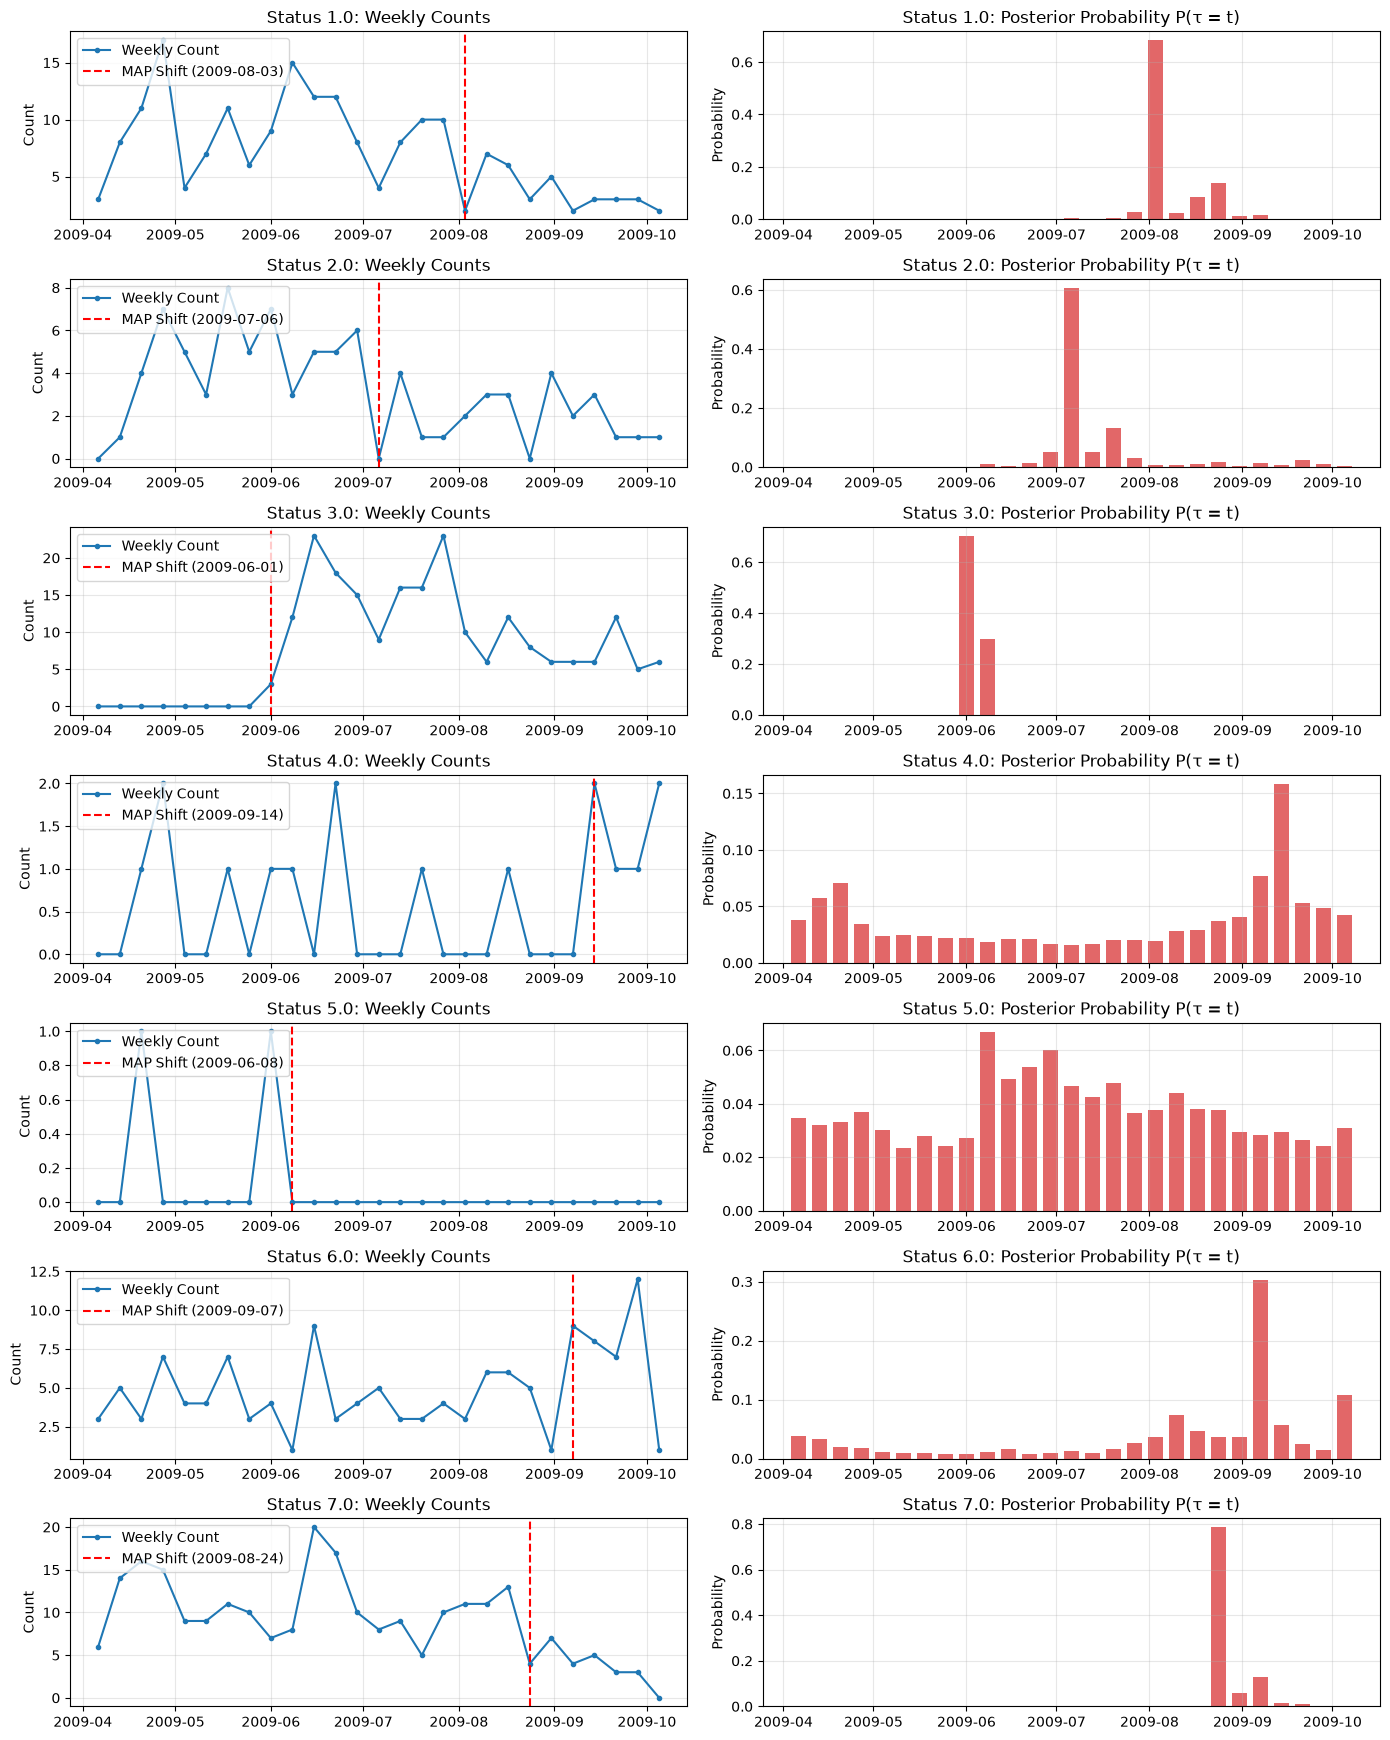

In [11]:
import pymc as pm
import matplotlib.pyplot as plt
import arviz as az

# 1. Prepare weekly datetime index
df_weekly = callstatus_weekly.copy()
df_weekly.index = pd.to_datetime(df_weekly.index)

# Dictionary to store Bayesian inference outputs
bayesian_results = {}

for col in df_weekly.columns:
    count_data = df_weekly[col].values
    n_count_data = len(count_data)
    idx = np.arange(n_count_data)
    
    # Define hyperprior rate based on overall mean
    mean_count = count_data.mean()
    alpha = 1.0 / mean_count if mean_count > 0 else 1.0

    with pm.Model() as model:
        # Uniform prior over all possible switchpoint weeks
        tau = pm.DiscreteUniform("tau", lower=0, upper=n_count_data - 1)

        # Exponential priors for pre- and post-changepoint arrival rates
        lambda_1 = pm.Exponential("lambda_1", alpha)
        lambda_2 = pm.Exponential("lambda_2", alpha)

        # Switch condition based on step function
        lambda_ = pm.math.switch(tau > idx, lambda_1, lambda_2)

        # Poisson likelihood for discrete counts
        observation = pm.Poisson("obs", lambda_, observed=count_data)

        # MCMC Sampling
        trace = pm.sample(
            draws=2000, 
            tune=1000, 
            return_inferencedata=True, 
            progressbar=False,
            random_seed=42
        )

    # Extract posterior probability distribution for tau
    tau_samples = trace.posterior["tau"].values.flatten()
    tau_pmf = np.bincount(tau_samples, minlength=n_count_data) / len(tau_samples)
    
    # Identify the MAP (Maximum A Posteriori) switchpoint index and date
    map_tau_idx = np.argmax(tau_pmf)
    map_date = df_weekly.index[map_tau_idx].strftime('%Y-%m-%d')
    
    # Store results
    bayesian_results[col] = {
        "trace": trace,
        "tau_pmf": tau_pmf,
        "map_date": map_date,
        "map_idx": map_tau_idx,
        "lambda_1_mean": trace.posterior["lambda_1"].mean().item(),
        "lambda_2_mean": trace.posterior["lambda_2"].mean().item(),
    }
    
    print(f"Status {col} MAP Changepoint Date: {map_date}")
    print(f"  Pre-shift Rate (λ1):  {bayesian_results[col]['lambda_1_mean']:.2f} calls/week")
    print(f"  Post-shift Rate (λ2): {bayesian_results[col]['lambda_2_mean']:.2f} calls/week\n")

# 2. Visualization (Data + Posterior Switchpoint Probability)
fig, axes = plt.subplots(len(df_weekly.columns), 2, figsize=(14, 2.5 * len(df_weekly.columns)))

if len(df_weekly.columns) == 1:
    axes = np.array([axes])

for i, col in enumerate(df_weekly.columns):
    res = bayesian_results[col]
    
    # Left subplot: Call status counts + detected MAP switchpoint
    axes[i, 0].plot(df_weekly.index, df_weekly[col], color="tab:blue", marker="o", markersize=3, label="Weekly Count")
    axes[i, 0].axvline(x=pd.to_datetime(res["map_date"]), color="red", linestyle="--", label=f"MAP Shift ({res['map_date']})")
    axes[i, 0].set_title(f"Status {col}: Weekly Counts")
    axes[i, 0].set_ylabel("Count")
    axes[i, 0].legend(loc="upper left")
    axes[i, 0].grid(True, alpha=0.3)
    
    # Right subplot: Posterior Probability Density for Switchpoint Tau
    axes[i, 1].bar(df_weekly.index, res["tau_pmf"], color="tab:red", width=5, alpha=0.7)
    axes[i, 1].set_title(f"Status {col}: Posterior Probability P(τ = t)")
    axes[i, 1].set_ylabel("Probability")
    axes[i, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Interpretation

The strongest finding from the temporal analysis is therefore not that all aspects of lead quality deteriorated. Rather, the evidence points specifically toward a deterioration in the probability that a lead ultimately becomes a closed lead.

The key results can be summarized as follows:
1. The overall closed-lead rate in the dataset is approximately \(8.1\%\).
2. There is a statistically significant temporal decline in the closed-lead rate.
3. A major candidate changepoint occurs around 17 August 2009.
4. The closed-lead rate falls from approximately \(8.82\%\) before this date to \(4.91\%\) afterwards.
5. The corresponding decline is approximately \(44\%\) relative to the pre-changepoint rate.
6. The bootstrap-adjusted significance of the selected changepoint is approximately \(p=0.012\).
7. There is no statistically significant evidence for a changepoint in the qualified-lead rate.
8. The qualified-lead rate actually increases slightly from approximately \(12.79\%\) to \(14.00\%\), although this difference is not statistically significant.
9. The temporal deterioration therefore appears to occur primarily between the "qualified" and "closed" stages of the lead funnel.

This last observation is particularly important from a business perspective. If the definition of lead quality is the probability of ultimately closing, then monitoring only an intermediate qualification event would fail to detect the deterioration observed in the latter part of the dataset.

The analysis also suggests that the change should not automatically be interpreted as a deterioration in the intrinsic quality of all incoming leads. A changepoint is an association with time, not a causal explanation. Changes in advertising campaigns, traffic sources, ad-group composition, applicant characteristics, sales processes, or operational handling could all produce the observed temporal pattern.

Consequently, the August changepoint should be treated as a \emph{diagnostic signal}. The next step would be to compare the composition of leads before and after 17 August across the variables identified earlier as important drivers of quality, particularly \texttt{AdGroupFamily}, \texttt{MarketingCampaign}, \texttt{Partner}, and \texttt{DebtLevelNo}. If the composition of incoming traffic changed substantially at approximately the same time, this would provide a plausible explanation for the temporal deterioration.

\subsection{Conclusion}

\begin{figure}[h]
	\centering
	\includegraphics[width=0.48\textwidth]{fig/changepoint_closed_rate}
	\includegraphics[width=0.48\textwidth]{fig/changepoint_counts}
\end{figure}
\begin{figure}[h]
	\centering
	\includegraphics[width=0.48\textwidth]{fig/changepoint_likelihood_ratio}
	\includegraphics[width=0.48\textwidth]{fig/changepoint_qualified_rate}
\end{figure}

Overall, the temporal analysis provides evidence of a meaningful decline in final lead quality during the observation period. The evidence is considerably stronger for the closed-lead rate than for the broader qualified-lead rate.

The most important temporal event is a changepoint around 17 August 2009, after which the closed-lead rate falls from approximately \(8.8\%\) to \(4.9\%\). Both the frequentist changepoint analysis and the smooth-rate regression indicate statistically significant deterioration, although the Bayesian analysis appropriately highlights the uncertainty in the exact location of the changepoint given the short time series.

Therefore, the data support the conclusion that \textbf{lead quality, when measured by eventual closure, declined materially during the latter part of the observation period}. The analysis does not, however, establish why this happened. Identifying the cause requires comparing the mix of campaigns, partners, ad groups, creatives, and applicant characteristics before and after the August changepoint.